In [1]:

from pathlib import Path
import random
import json
import time

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from tokenizers import Tokenizer

# Project paths
DATA_DIR = Path("/srv/data/lt2326-h26/a1")
TOKENIZER_DIR = Path("tokenizer/tokenizers")
CHECKPOINT_DIR = Path("../checkpoints")
RESULTS_DIR = Path("../results")

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Device
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Model settings
CONTEXT_LENGTH = 128
BATCH_SIZE = 16
HIDDEN_SIZE = 128
NUM_HEADS = 4
NUM_LAYERS = 2
DROPOUT = 0.1

print("Setup complete.")

Device: cuda
GPU: NVIDIA GeForce GTX 1080 Ti
Setup complete.


In [2]:

# Load the training and validation text

LANGUAGES = ["en", "tr", "zh"]

train_texts = {}
valid_texts = {}

for lang in LANGUAGES:
    train_path = DATA_DIR / "train" / f"{lang}.txt"
    valid_path = DATA_DIR / "valid" / f"{lang}.txt"

    train_texts[lang] = train_path.read_text(encoding="utf-8")
    valid_texts[lang] = valid_path.read_text(encoding="utf-8")

    print(
        f"{lang.upper()}: "
        f"{len(train_texts[lang]):,} training characters, "
        f"{len(valid_texts[lang]):,} validation characters"
    )

# Load the two BPE tokenizers
bpe_2k = Tokenizer.from_file(str(TOKENIZER_DIR / "bpe_2k.json"))
bpe_10k = Tokenizer.from_file(str(TOKENIZER_DIR / "bpe_10k.json"))

print("\nBPE-2K vocabulary:", bpe_2k.get_vocab_size())
print("BPE-10K vocabulary:", bpe_10k.get_vocab_size())

# Build the character vocabulary using training data only
all_training_text = "".join(train_texts[lang] for lang in LANGUAGES)

characters = sorted(set(all_training_text))

# ID 0 is reserved for characters not seen during training
stoi = {"<UNK>": 0}

for character in characters:
    if character not in stoi:
        stoi[character] = len(stoi)

itos = {index: character for character, index in stoi.items()}

print("Character vocabulary:", len(stoi))


# Convert text to token IDs
def encode_text(text, tokenizer_name):
    if tokenizer_name == "character":
        return [stoi.get(character, 0) for character in text]

    elif tokenizer_name == "bpe_2k":
        return bpe_2k.encode(text).ids

    elif tokenizer_name == "bpe_10k":
        return bpe_10k.encode(text).ids

    else:
        raise ValueError("Unknown tokenizer: " + tokenizer_name)


# Prepare training and validation tensors
tokenizer_names = ["character", "bpe_2k", "bpe_10k"]

vocab_sizes = {
    "character": len(stoi),
    "bpe_2k": bpe_2k.get_vocab_size(),
    "bpe_10k": bpe_10k.get_vocab_size()
}

train_data = {}
valid_data = {}

for tokenizer_name in tokenizer_names:
    train_data[tokenizer_name] = {}
    valid_data[tokenizer_name] = {}

    for lang in LANGUAGES:
        train_ids = encode_text(train_texts[lang], tokenizer_name)
        valid_ids = encode_text(valid_texts[lang], tokenizer_name)

        train_data[tokenizer_name][lang] = torch.tensor(
            train_ids, dtype=torch.long
        )
        valid_data[tokenizer_name][lang] = torch.tensor(
            valid_ids, dtype=torch.long
        )

        print(
            f"{tokenizer_name:10} {lang.upper()}: "
            f"{len(train_ids):,} train tokens, "
            f"{len(valid_ids):,} validation tokens"
        )

print("\nData and tokenizers loaded successfully.")

EN: 2,982,219 training characters, 372,809 validation characters
TR: 2,976,519 training characters, 372,118 validation characters
ZH: 3,022,139 training characters, 377,820 validation characters

BPE-2K vocabulary: 2000
BPE-10K vocabulary: 10000
Character vocabulary: 9444
character  EN: 2,982,219 train tokens, 372,809 validation tokens
character  TR: 2,976,519 train tokens, 372,118 validation tokens
character  ZH: 3,022,139 train tokens, 377,820 validation tokens
bpe_2k     EN: 1,363,691 train tokens, 170,973 validation tokens
bpe_2k     TR: 1,380,794 train tokens, 172,678 validation tokens
bpe_2k     ZH: 3,357,246 train tokens, 420,823 validation tokens
bpe_10k    EN: 968,065 train tokens, 121,624 validation tokens
bpe_10k    TR: 948,949 train tokens, 119,295 validation tokens
bpe_10k    ZH: 2,428,594 train tokens, 305,372 validation tokens

Data and tokenizers loaded successfully.


In [6]:

# Create a batch of input sequences and next-token targets

def get_batch(tokenizer_name, batch_size=16, context_length=128):
    language_data = train_data[tokenizer_name]

    inputs = []
    targets = []

    for _ in range(batch_size):
        # Choose a language
        lang = random.choice(LANGUAGES)
        data = language_data[lang]

        # Choose a random starting position
        max_start = len(data) - context_length - 1
        start = torch.randint(0, max_start + 1, (1,)).item()

        # Input tokens and their next-token targets
        input_sequence = data[start : start + context_length]
        target_sequence = data[start + 1 : start + context_length + 1]

        inputs.append(input_sequence)
        targets.append(target_sequence)

    # Combine examples into batches and move them to the GPU
    inputs = torch.stack(inputs).to(device)
    targets = torch.stack(targets).to(device)

    return inputs, targets


print("Batch function defined successfully.")

Batch function defined successfully.


# Implementing the decoder-only transformer


In [3]:

# Decoder-only Transformer language model

class DecoderOnlyTransformer(nn.Module):
    def __init__(
        self,
        vocab_size,
        context_length=128,
        hidden_size=128,
        num_heads=4,
        num_layers=2,
        dropout=0.1
    ):
        super().__init__()

        # Convert token IDs into vectors
        self.token_embedding = nn.Embedding(vocab_size, hidden_size)

        # Add information about token positions
        self.position_embedding = nn.Embedding(
            context_length, hidden_size
        )

        # Create one Transformer block
        transformer_layer = nn.TransformerEncoderLayer(
            d_model=hidden_size,
            nhead=num_heads,
            dim_feedforward=4 * hidden_size,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )

        # Stack two Transformer blocks
        self.transformer = nn.TransformerEncoder(
            transformer_layer,
            num_layers=num_layers
        )

        self.final_norm = nn.LayerNorm(hidden_size)

        # Predict the next token
        self.output_layer = nn.Linear(hidden_size, vocab_size)

        self.context_length = context_length

    def forward(self, input_ids, targets=None):
        batch_size, sequence_length = input_ids.shape

        # Create position IDs: 0, 1, 2, ...
        positions = torch.arange(
            sequence_length, device=input_ids.device
        )

        # Combine token embeddings and position embeddings
        x = (
            self.token_embedding(input_ids)
            + self.position_embedding(positions)
        )

        # Block access to future tokens
        causal_mask = torch.triu(
            torch.ones(
                sequence_length,
                sequence_length,
                device=input_ids.device,
                dtype=torch.bool
            ),
            diagonal=1
        )

        # Process tokens using the Transformer
        x = self.transformer(x, mask=causal_mask)
        x = self.final_norm(x)

        # Predict a score for every possible next token
        logits = self.output_layer(x)

        loss = None

        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1)
            )

        return logits, loss


print("Transformer class defined successfully.")

Transformer class defined successfully.


In [4]:

# Count the parameters for each tokenizer's model

for tokenizer_name in tokenizer_names:
    model = DecoderOnlyTransformer(
        vocab_size=vocab_sizes[tokenizer_name],
        context_length=CONTEXT_LENGTH,
        hidden_size=HIDDEN_SIZE,
        num_heads=NUM_HEADS,
        num_layers=NUM_LAYERS,
        dropout=DROPOUT
    )

    total_params = sum(
        parameter.numel() for parameter in model.parameters()
    )

    input_embedding_params = sum(
        parameter.numel()
        for parameter in model.token_embedding.parameters()
    )

    output_layer_params = sum(
        parameter.numel()
        for parameter in model.output_layer.parameters()
    )

    print(f"\n{tokenizer_name}")
    print("Vocabulary size:", vocab_sizes[tokenizer_name])
    print("Total parameters:", f"{total_params:,}")
    print("Input embedding parameters:", f"{input_embedding_params:,}")
    print("Output layer parameters:", f"{output_layer_params:,}")

    del model


character
Vocabulary size: 9444
Total parameters: 2,840,292
Input embedding parameters: 1,208,832
Output layer parameters: 1,218,276

bpe_2k
Vocabulary size: 2000
Total parameters: 927,184
Input embedding parameters: 256,000
Output layer parameters: 258,000

bpe_10k
Vocabulary size: 10000
Total parameters: 2,983,184
Input embedding parameters: 1,280,000
Output layer parameters: 1,290,000


In [7]:

# Test the model on a BPE-2K batch

test_inputs, test_targets = get_batch(
    "bpe_2k",
    batch_size=BATCH_SIZE,
    context_length=CONTEXT_LENGTH
)

test_model = DecoderOnlyTransformer(
    vocab_size=vocab_sizes["bpe_2k"],
    context_length=CONTEXT_LENGTH,
    hidden_size=HIDDEN_SIZE,
    num_heads=NUM_HEADS,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT
).to(device)

logits, loss = test_model(test_inputs, test_targets)

print("Input shape:", test_inputs.shape)
print("Output shape:", logits.shape)
print("Initial loss:", loss.item())
print("Test successful:", torch.isfinite(loss).item())

del test_model

Input shape: torch.Size([16, 128])
Output shape: torch.Size([16, 128, 2000])
Initial loss: 7.75277853012085
Test successful: True


In [8]:
#Add the training settings and validation function

# Training settings
LEARNING_RATE = 3e-4
MAX_STEPS = 1500
EVAL_INTERVAL = 100
EVAL_BATCHES = 20

# Make the experiment more reproducible
random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)


# Create a batch from either training or validation data
def get_batch_from(data_source, tokenizer_name,
                   batch_size=16, context_length=128):

    language_data = data_source[tokenizer_name]

    inputs = []
    targets = []

    for _ in range(batch_size):
        lang = random.choice(LANGUAGES)
        data = language_data[lang]

        max_start = len(data) - context_length - 1
        start = torch.randint(0, max_start + 1, (1,)).item()

        inputs.append(data[start:start + context_length])
        targets.append(data[start + 1:start + context_length + 1])

    inputs = torch.stack(inputs).to(device)
    targets = torch.stack(targets).to(device)

    return inputs, targets


# Measure average loss without updating the model
@torch.no_grad()
def estimate_loss(model, tokenizer_name):
    model.eval()

    losses = {"train": [], "valid": []}

    for split, data_source in [
        ("train", train_data),
        ("valid", valid_data)
    ]:
        for _ in range(EVAL_BATCHES):
            x, y = get_batch_from(
                data_source, tokenizer_name,
                BATCH_SIZE, CONTEXT_LENGTH
            )

            _, loss = model(x, y)
            losses[split].append(loss.item())

    model.train()

    return {
        split: sum(values) / len(values)
        for split, values in losses.items()
    }


print("Training settings and validation function ready.")

Training settings and validation function ready.


In [9]:

training_histories = {}

for tokenizer_name in tokenizer_names:
    print(f"\nTraining model: {tokenizer_name}")

    model = DecoderOnlyTransformer(
        vocab_size=vocab_sizes[tokenizer_name],
        context_length=CONTEXT_LENGTH,
        hidden_size=HIDDEN_SIZE,
        num_heads=NUM_HEADS,
        num_layers=NUM_LAYERS,
        dropout=DROPOUT
    ).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=0.01
    )

    history = {
        "step": [],
        "train_loss": [],
        "valid_loss": []
    }

    best_valid_loss = float("inf")
    start_time = time.time()

    for step in range(1, MAX_STEPS + 1):
        model.train()

        x, y = get_batch(
            tokenizer_name,
            batch_size=BATCH_SIZE,
            context_length=CONTEXT_LENGTH
        )

        _, loss = model(x, y)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()

        # Prevent unusually large gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()

        if step == 1 or step % EVAL_INTERVAL == 0:
            results = estimate_loss(model, tokenizer_name)

            history["step"].append(step)
            history["train_loss"].append(results["train"])
            history["valid_loss"].append(results["valid"])

            print(
                f"Step {step:4d}/{MAX_STEPS} | "
                f"Train loss: {results['train']:.4f} | "
                f"Validation loss: {results['valid']:.4f}"
            )

            if results["valid"] < best_valid_loss:
                best_valid_loss = results["valid"]

                torch.save(
                    {
                        "model_state_dict": model.state_dict(),
                        "tokenizer_name": tokenizer_name,
                        "vocab_size": vocab_sizes[tokenizer_name],
                        "context_length": CONTEXT_LENGTH,
                        "hidden_size": HIDDEN_SIZE,
                        "num_heads": NUM_HEADS,
                        "num_layers": NUM_LAYERS,
                        "dropout": DROPOUT,
                        "step": step,
                        "valid_loss": best_valid_loss
                    },
                    CHECKPOINT_DIR / f"{tokenizer_name}_best.pt"
                )

    training_histories[tokenizer_name] = history

    # Save the complete loss history
    with open(
        RESULTS_DIR / f"{tokenizer_name}_loss.json",
        "w",
        encoding="utf-8"
    ) as file:
        json.dump(history, file, indent=2)

    elapsed = (time.time() - start_time) / 60

    print(f"Best validation loss: {best_valid_loss:.4f}")
    print(f"Training time: {elapsed:.1f} minutes")

    del model, optimizer

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nAll three training runs completed.")


Training model: character
Step    1/1500 | Train loss: 9.2410 | Validation loss: 9.2401
Step  100/1500 | Train loss: 4.7959 | Validation loss: 4.9865
Step  200/1500 | Train loss: 4.1057 | Validation loss: 4.2985
Step  300/1500 | Train loss: 4.1918 | Validation loss: 4.1665
Step  400/1500 | Train loss: 3.8733 | Validation loss: 3.9469
Step  500/1500 | Train loss: 3.7721 | Validation loss: 3.8319
Step  600/1500 | Train loss: 3.7114 | Validation loss: 3.8219
Step  700/1500 | Train loss: 3.8158 | Validation loss: 3.8854
Step  800/1500 | Train loss: 3.9798 | Validation loss: 3.8800
Step  900/1500 | Train loss: 3.8186 | Validation loss: 3.6182
Step 1000/1500 | Train loss: 3.9168 | Validation loss: 3.8384
Step 1100/1500 | Train loss: 3.8588 | Validation loss: 3.7191
Step 1200/1500 | Train loss: 3.5817 | Validation loss: 3.7402
Step 1300/1500 | Train loss: 3.6470 | Validation loss: 3.7341
Step 1400/1500 | Train loss: 3.7289 | Validation loss: 3.7385
Step 1500/1500 | Train loss: 3.6645 | Valid

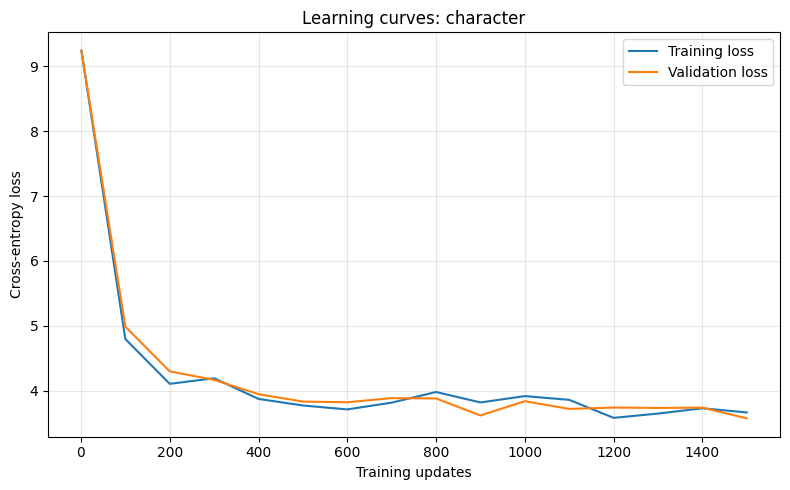

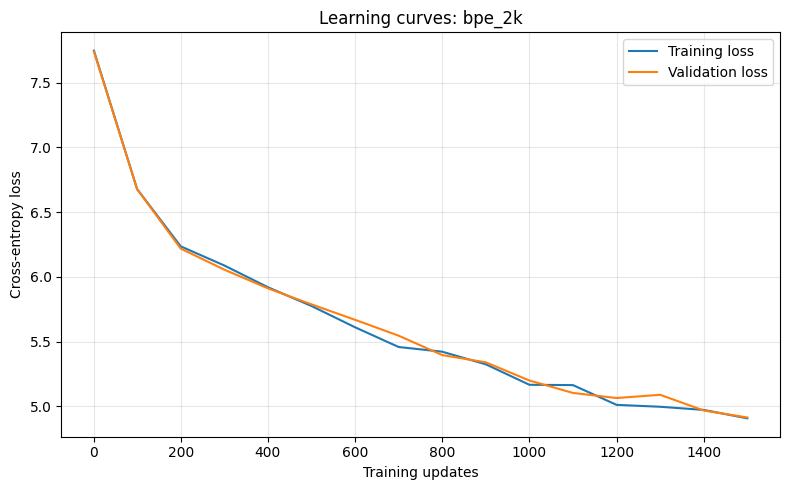

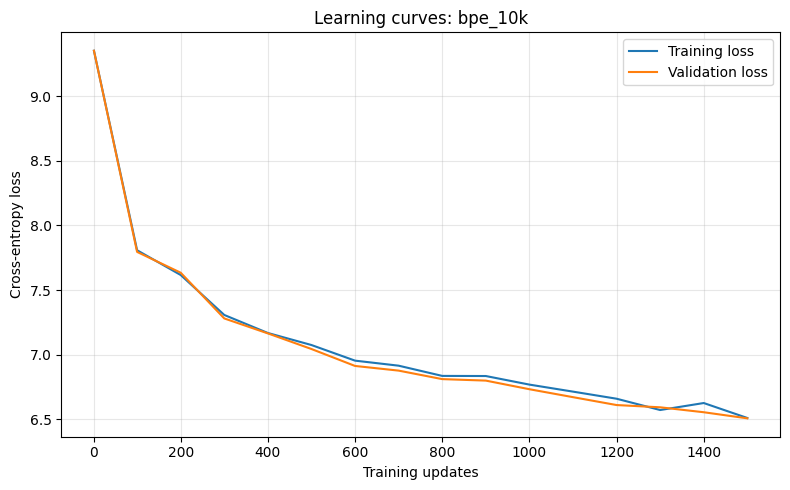

In [10]:

# Compare training and validation loss

for tokenizer_name, history in training_histories.items():
    plt.figure(figsize=(8, 5))

    plt.plot(
        history["step"],
        history["train_loss"],
        label="Training loss"
    )

    plt.plot(
        history["step"],
        history["valid_loss"],
        label="Validation loss"
    )

    plt.xlabel("Training updates")
    plt.ylabel("Cross-entropy loss")
    plt.title(f"Learning curves: {tokenizer_name}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        RESULTS_DIR / f"{tokenizer_name}_learning_curve.png",
        dpi=150
    )

    plt.show()

In [11]:

# Summarize the best and final validation losses

for tokenizer_name in tokenizer_names:
    history_path = RESULTS_DIR / f"{tokenizer_name}_loss.json"

    with open(history_path, encoding="utf-8") as file:
        history = json.load(file)

    best_index = history["valid_loss"].index(
        min(history["valid_loss"])
    )

    print(f"\n{tokenizer_name}")
    print("Best validation loss:",
          round(history["valid_loss"][best_index], 4))
    print("Best step:", history["step"][best_index])
    print("Final training loss:",
          round(history["train_loss"][-1], 4))
    print("Final validation loss:",
          round(history["valid_loss"][-1], 4))


character
Best validation loss: 3.5738
Best step: 1500
Final training loss: 3.6645
Final validation loss: 3.5738

bpe_2k
Best validation loss: 4.9144
Best step: 1500
Final training loss: 4.9079
Final validation loss: 4.9144

bpe_10k
Best validation loss: 6.506
Best step: 1500
Final training loss: 6.5088
Final validation loss: 6.506


In [12]:

import math
import pandas as pd

# Load the test text
test_texts = {}

for lang in LANGUAGES:
    test_path = DATA_DIR / "test" / f"{lang}.txt"
    test_texts[lang] = test_path.read_text(encoding="utf-8")

    print(f"{lang.upper()} test characters:",
          f"{len(test_texts[lang]):,}")


@torch.no_grad()
def evaluate_test(model, token_ids, original_text):
    model.eval()

    # Predict every token except the first one.
    # Each chunk starts a fresh context of up to 128 tokens.
    chunks = []

    for start in range(0, len(token_ids) - 1, CONTEXT_LENGTH):
        end = min(start + CONTEXT_LENGTH, len(token_ids) - 1)

        x = token_ids[start:end]
        y = token_ids[start + 1:end + 1]

        chunks.append((x, y))

    total_nll = 0.0
    total_tokens = 0
    eval_batch_size = 16

    for start in range(0, len(chunks), eval_batch_size):
        batch_chunks = chunks[start:start + eval_batch_size]
        max_length = max(len(x) for x, y in batch_chunks)

        batch_x = []
        batch_y = []

        for x, y in batch_chunks:
            # Pad the final short chunk
            padded_x = F.pad(
                x, (0, max_length - len(x)), value=0
            )
            padded_y = F.pad(
                y, (0, max_length - len(y)), value=-100
            )

            batch_x.append(padded_x)
            batch_y.append(padded_y)

        batch_x = torch.stack(batch_x).to(device)
        batch_y = torch.stack(batch_y).to(device)

        logits, _ = model(batch_x)

        # Sum negative log-likelihood over real target tokens
        nll = F.cross_entropy(
            logits.reshape(-1, logits.size(-1)),
            batch_y.reshape(-1),
            ignore_index=-100,
            reduction="sum"
        )

        total_nll += nll.item()
        total_tokens += (batch_y != -100).sum().item()

    average_loss = total_nll / total_tokens
    bpc = total_nll / (len(original_text) * math.log(2))

    return {
        "test_tokens": total_tokens,
        "cross_entropy": average_loss,
        "token_perplexity": math.exp(average_loss),
        "BPC": bpc
    }


# Evaluate each saved best checkpoint on all three languages
test_results = []

for tokenizer_name in tokenizer_names:
    checkpoint_path = (
        CHECKPOINT_DIR / f"{tokenizer_name}_best.pt"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    model = DecoderOnlyTransformer(
        vocab_size=vocab_sizes[tokenizer_name],
        context_length=CONTEXT_LENGTH,
        hidden_size=HIDDEN_SIZE,
        num_heads=NUM_HEADS,
        num_layers=NUM_LAYERS,
        dropout=DROPOUT
    ).to(device)

    model.load_state_dict(checkpoint["model_state_dict"])

    print(f"\nEvaluating {tokenizer_name}...")

    for lang in LANGUAGES:
        token_ids = torch.tensor(
            encode_text(test_texts[lang], tokenizer_name),
            dtype=torch.long
        )

        metrics = evaluate_test(
            model, token_ids, test_texts[lang]
        )

        row = {
            "tokenizer": tokenizer_name,
            "language": lang.upper(),
            **metrics
        }
        test_results.append(row)

        print(
            f"{lang.upper()}: "
            f"cross-entropy={metrics['cross_entropy']:.4f}, "
            f"BPC={metrics['BPC']:.4f}"
        )

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# Save the evaluation results
results_df = pd.DataFrame(test_results)
results_df.to_csv(
    RESULTS_DIR / "test_results.csv", index=False
)

results_df

EN test characters: 372,781
TR test characters: 372,134
ZH test characters: 377,695

Evaluating character...
EN: cross-entropy=2.5058, BPC=3.6151
TR: cross-entropy=2.6039, BPC=3.7566
ZH: cross-entropy=5.9419, BPC=8.5723

Evaluating bpe_2k...
EN: cross-entropy=4.4762, BPC=2.9450
TR: cross-entropy=4.6044, BPC=3.0913
ZH: cross-entropy=5.6767, BPC=9.1336

Evaluating bpe_10k...
EN: cross-entropy=5.8673, BPC=2.7425
TR: cross-entropy=6.4355, BPC=2.9785
ZH: cross-entropy=7.3169, BPC=8.5198


,tokenizer,language,test_tokens,cross_entropy,token_perplexity,BPC
0,character,EN,372780,2.505815,12.253547,3.615118
1,character,TR,372133,2.603911,13.516495,3.756639
2,character,ZH,377694,5.941915,380.663143,8.572348
3,bpe_2k,EN,170006,4.476163,87.896737,2.945038
4,bpe_2k,TR,173178,4.604399,99.922940,3.091298
5,bpe_2k,ZH,421223,5.676727,291.992260,9.133630
6,bpe_10k,EN,120778,5.867339,353.307540,2.742520
7,bpe_10k,TR,119384,6.435499,623.593706,2.978541
8,bpe_10k,ZH,304837,7.316920,1505.559497,8.519798


In [13]:

from collections import Counter
from itertools import combinations
import pandas as pd

# Count how often each BPE token occurs in each language
bpe_tokenizers = {
    "bpe_2k": bpe_2k,
    "bpe_10k": bpe_10k
}

vocabulary_results = []

for tokenizer_name, tokenizer in bpe_tokenizers.items():
    language_token_counts = {}

    for lang in LANGUAGES:
        token_ids = tokenizer.encode(train_texts[lang]).ids
        language_token_counts[lang] = Counter(token_ids)

    # Find the token IDs that occur in each language
    language_token_sets = {
        lang: set(counts.keys())
        for lang, counts in language_token_counts.items()
    }

    print(f"\nVocabulary sharing: {tokenizer_name}")
    print("Total tokenizer vocabulary:", tokenizer.get_vocab_size())

    # Count tokens used by exactly these language combinations
    for number_of_languages in range(1, 4):
        for group in combinations(LANGUAGES, number_of_languages):
            used_by_group = set.intersection(
                *(language_token_sets[lang] for lang in group)
            )

            # Remove tokens also used by languages outside this group
            other_languages = [
                lang for lang in LANGUAGES if lang not in group
            ]

            for other_lang in other_languages:
                used_by_group -= language_token_sets[other_lang]

            group_name = " + ".join(lang.upper() for lang in group)

            vocabulary_results.append({
                "tokenizer": tokenizer_name,
                "language_group": group_name,
                "token_types": len(used_by_group)
            })

            print(f"{group_name:12}: {len(used_by_group):,} token types")

    # How many vocabulary entries are used at least once?
    used_anywhere = set.union(*language_token_sets.values())
    print("Distinct tokens used in any language:", len(used_anywhere))
    print("Unused vocabulary entries:",
          tokenizer.get_vocab_size() - len(used_anywhere))


vocabulary_df = pd.DataFrame(vocabulary_results)

vocabulary_df.to_csv(
    RESULTS_DIR / "bpe_vocabulary_sharing.csv",
    index=False
)

vocabulary_df


Vocabulary sharing: bpe_2k
Total tokenizer vocabulary: 2000
EN          : 4 token types
TR          : 125 token types
ZH          : 809 token types
EN + TR     : 43 token types
EN + ZH     : 167 token types
TR + ZH     : 48 token types
EN + TR + ZH: 738 token types
Distinct tokens used in any language: 1934
Unused vocabulary entries: 66

Vocabulary sharing: bpe_10k
Total tokenizer vocabulary: 10000
EN          : 351 token types
TR          : 1,408 token types
ZH          : 4,653 token types
EN + TR     : 354 token types
EN + ZH     : 522 token types
TR + ZH     : 91 token types
EN + TR + ZH: 2,535 token types
Distinct tokens used in any language: 9914
Unused vocabulary entries: 86


,tokenizer,language_group,token_types
0,bpe_2k,EN,4
1,bpe_2k,TR,125
2,bpe_2k,ZH,809
3,bpe_2k,EN + TR,43
4,bpe_2k,EN + ZH,167
5,bpe_2k,TR + ZH,48
6,bpe_2k,EN + TR + ZH,738
7,bpe_10k,EN,351
8,bpe_10k,TR,1408
9,bpe_10k,ZH,4653


In [14]:

# Summarize training results and model sizes

summary_rows = []

for tokenizer_name in tokenizer_names:
    # Load the recorded loss history
    with open(
        RESULTS_DIR / f"{tokenizer_name}_loss.json",
        encoding="utf-8"
    ) as file:
        history = json.load(file)

    best_index = history["valid_loss"].index(
        min(history["valid_loss"])
    )

    # Recreate the model to count its parameters
    model = DecoderOnlyTransformer(
        vocab_size=vocab_sizes[tokenizer_name],
        context_length=CONTEXT_LENGTH,
        hidden_size=HIDDEN_SIZE,
        num_heads=NUM_HEADS,
        num_layers=NUM_LAYERS,
        dropout=DROPOUT
    )

    total_params = sum(
        p.numel() for p in model.parameters()
    )

    embedding_params = sum(
        p.numel() for p in model.token_embedding.parameters()
    )

    output_params = sum(
        p.numel() for p in model.output_layer.parameters()
    )

    summary_rows.append({
        "tokenizer": tokenizer_name,
        "vocabulary_size": vocab_sizes[tokenizer_name],
        "total_parameters": total_params,
        "input_embedding_parameters": embedding_params,
        "output_layer_parameters": output_params,
        "best_validation_loss": history["valid_loss"][best_index],
        "best_step": history["step"][best_index],
        "final_train_loss": history["train_loss"][-1],
        "final_validation_loss": history["valid_loss"][-1]
    })

    del model

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(
    RESULTS_DIR / "training_summary.csv", index=False
)

summary_df.round(4)

,tokenizer,vocabulary_size,total_parameters,input_embedding_parameters,output_layer_parameters,best_validation_loss,best_step,final_train_loss,final_validation_loss
0,character,9444,2840292,1208832,1218276,3.5738,1500,3.6645,3.5738
1,bpe_2k,2000,927184,256000,258000,4.9144,1500,4.9079,4.9144
2,bpe_10k,10000,2983184,1280000,1290000,6.5060,1500,6.5088,6.5060


In [15]:

# Print the complete summary without truncating columns

print(summary_df.to_string(index=False))

# Check the saved loss history for each model
for tokenizer_name in tokenizer_names:
    path = RESULTS_DIR / f"{tokenizer_name}_loss.json"

    print(f"\n--- {tokenizer_name} ---")

    if not path.exists():
        print("Loss history file is missing!")
        continue

    with open(path, encoding="utf-8") as file:
        history = json.load(file)

    best_index = history["valid_loss"].index(
        min(history["valid_loss"])
    )

    print("Number of recorded evaluations:", len(history["step"]))
    print("Best validation loss:", history["valid_loss"][best_index])
    print("Best step:", history["step"][best_index])
    print("Final training loss:", history["train_loss"][-1])
    print("Final validation loss:", history["valid_loss"][-1])

tokenizer  vocabulary_size  total_parameters  input_embedding_parameters  output_layer_parameters  best_validation_loss  best_step  final_train_loss  final_validation_loss
character             9444           2840292                     1208832                  1218276              3.573820       1500          3.664516               3.573820
   bpe_2k             2000            927184                      256000                   258000              4.914376       1500          4.907855               4.914376
  bpe_10k            10000           2983184                     1280000                  1290000              6.505969       1500          6.508770               6.505969

--- character ---
Number of recorded evaluations: 16
Best validation loss: 3.5738202333450317
Best step: 1500
Final training loss: 3.664515721797943
Final validation loss: 3.5738202333450317

--- bpe_2k ---
Number of recorded evaluations: 16
Best validation loss: 4.914375567436219
Best step: 1500
Final trainin

In [16]:

# Check that all learning curves were saved

for tokenizer_name in tokenizer_names:
    plot_path = (
        RESULTS_DIR / f"{tokenizer_name}_learning_curve.png"
    )

    print(
        tokenizer_name,
        "->",
        "Saved" if plot_path.exists() else "Missing",
        plot_path
    )

character -> Saved ../results/character_learning_curve.png
bpe_2k -> Saved ../results/bpe_2k_learning_curve.png
bpe_10k -> Saved ../results/bpe_10k_learning_curve.png
